In [2]:
#!/usr/bin/env python3 

In [76]:
# Importing the necessary modules 
import io 
import os 
import tensorflow as tf 
from PIL import Image 
from transformers import pipeline 
from tensorflow.keras import layers, Model, Input

In [77]:
# Configurations for the model 
IMG_SIZE = 224 
VOCAB_SIZE = 500
EMBED_DIM = 256 
FF_DIM = 512 
NUM_HEADS = 4 
SEQ_LENGTH = 30 

In [78]:
# Building the vision encoder (pretrained CNN) model 
def build_vision_encoder(): 
    # Using EfficientNetBO as a feature extractor 
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    # Setting the base model trainable 
    base_model.trainable = False

    # setting the input shape 
    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base_model(inputs, training=False)

    # Global Average Pooling to get a 1D feature vector per image 
    x = layers.GlobalAveragePooling2D()(x) 

    # Project to the dimension expected by the decoder 
    outputs = layers.Dense(EMBED_DIM)(x) 

    # Returning the vision encoder  
    return Model(inputs, outputs, name="vision_encoder") 

In [79]:
# Creating a class for the Transformer Decoder Block 
class TransformerDecoderBlock(layers.Layer):
    # Creating the init method 
    def __init__(self, embed_dim, ff_dim, num_heads):
        super().__init__()
        self.self_attention = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.cross_attention = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = tf.keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim),
        ])
        self.layernorm1 = layers.LayerNormalization()
        self.layernorm2 = layers.LayerNormalization()
        self.layernorm3 = layers.LayerNormalization()
        self.dropout1 = layers.Dropout(0.1)
        self.dropout2 = layers.Dropout(0.1)
        self.dropout3 = layers.Dropout(0.1)

    # Creating the call method 
    def call(self, inputs, encoder_outputs, training, look_ahead_mask=None, padding_mask=None):
        # 1. Self-Attention (causal)
        attn1 = self.self_attention(query=inputs, key=inputs, value=inputs, attention_mask=look_ahead_mask)
        attn1 = self.dropout1(attn1, training=training)
        out1 = self.layernorm1(inputs + attn1)

        # 2. Cross-Attention (Image features as Key/Value)
        # Expand encoder_outputs to match the batch dimension of inputs
        encoder_outputs = tf.expand_dims(encoder_outputs, axis=1) 
        attn2 = self.cross_attention(query=out1, key=encoder_outputs, value=encoder_outputs)
        attn2 = self.dropout2(attn2, training=training)
        out2 = self.layernorm2(out1 + attn2)

        # 3. Feed Forward Network
        ffn_output = self.ffn(out2)
        ffn_output = self.dropout3(ffn_output, training=training)
        out3 = self.layernorm3(out2 + ffn_output)

        # Returning the out network 
        return out3

In [80]:
class PlantVLM(Model):
    def __init__(self, vision_encoder, vocab_size, embed_dim, seq_length, **kwargs):
        super().__init__(**kwargs)
        self.vision_encoder = vision_encoder
        self.token_embedding = layers.Embedding(vocab_size, embed_dim)
        self.pos_embedding   = layers.Embedding(seq_length, embed_dim)
        self.decoder_block   = TransformerDecoderBlock(embed_dim, FF_DIM, NUM_HEADS)
        self.final_layer     = layers.Dense(vocab_size)

    def call(self, inputs, training=False):
        # inputs is a tuple/list: (image, text_seq)
        image, text_seq = inputs[0], inputs[1]

        img_features = self.vision_encoder(image, training=False)

        seq_len = tf.shape(text_seq)[1]
        positions = tf.range(start=0, limit=seq_len, delta=1)
        text_emb = self.token_embedding(text_seq) + self.pos_embedding(positions)

        look_ahead_mask = tf.linalg.band_part(tf.ones((seq_len, seq_len)), -1, 0)
        look_ahead_mask = 1 - look_ahead_mask

        x = self.decoder_block(
            text_emb, img_features,
            training=training,
            look_ahead_mask=look_ahead_mask,
        )
        return self.final_layer(x)

In [81]:
# Initialize the encoder 
encoder = build_vision_encoder() 
vlm_model = PlantVLM(encoder, VOCAB_SIZE, EMBED_DIM, SEQ_LENGTH) 

In [82]:
# Summary of the model
vlm_model.build(input_shape=[(None, IMG_SIZE, IMG_SIZE, 3), (None, SEQ_LENGTH)])
vlm_model.summary()

/Users/mbonuchinedum/anaconda3/envs/ml/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'plant_vlm_10', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Model: "plant_vlm_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vision_encoder (Functional)     │ (None, 256)            │     4,377,507 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_22 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_23 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_decoder_block_11    │ ?                      │   0 (unbuilt) │
│ (TransformerDecoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,377,507 (16.70 MB)

 Trainable params: 327,936 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [83]:
# Creating a function for generating the caption 
def generate_caption(model, image_path, tokenizer, max_length=30):
    """
    image_path: Path to the plant image
    tokenizer: A fitted tokenizer (e.g., Keras Tokenizer)
    """
    # 1. Preprocess Image
    img = tf.keras.utils.load_img(image_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0) # Add batch dimension
    
    # 2. Start the sequence with the start token
    start_token = tokenizer.word_index.get('startseq', 1)
    end_token = tokenizer.word_index.get('endseq', 2)
    
    # Start with just the start token
    output_seq = [start_token]
    
    # 3. Generate words one by one
    for i in range(max_length):
        # Prepare the partial sequence
        padded_seq = tf.keras.preprocessing.sequence.pad_sequences([output_seq], maxlen=SEQ_LENGTH, padding='post')
        
        # Predict
        predictions = model.predict([img_array, padded_seq], verbose=0)
        
        # Get the last word's prediction (index i in the sequence)
        # Since we pad at the end, the last real token's prediction is at index len(output_seq)-1
        next_token_logits = predictions[0, len(output_seq)-1, :]
        next_token_id = tf.argmax(next_token_logits).numpy()
        
        # Break if we hit the end token
        if next_token_id == end_token:
            break
            
        output_seq.append(next_token_id)
    
    # 4. Convert IDs back to words
    # Skip the start token (index 0)
    generated_words = []
    for token_id in output_seq[1:]:
        word = tokenizer.index_word.get(token_id, '')
        if word:
            generated_words.append(word)
            
    return " ".join(generated_words)

In [84]:
# --- Example Usage ---
# Assuming you have a trained model and a fitted tokenizer...
# caption = generate_caption(vlm_model, "./dataset/images/img1.jpeg", tokenizer)

<h2> Training the Plant VLM from Scratch </h2>

In [85]:
import os
import json
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import matplotlib.pyplot as plt

# Config (must match model definition) ---
IMG_SIZE = 224
VOCAB_SIZE = 5000
EMBED_DIM = 256
FF_DIM = 512
NUM_HEADS = 4
SEQ_LENGTH = 30
BATCH_SIZE = 32
EPOCHS = 30

<h2> Load and Prepare the Dataset </h2> 
<p> Assume your dataset is structured as the following </p>

```bash

plant_vlm_dataset/
├── images/
│   ├── apple_healthy_001.jpg
│   └── ...
└── captions.json

```

In [86]:
# Setting the dataset directory 
DATA_DIR = "dataset"

# 
IMG_DIR = os.path.join(DATA_DIR, "images")
CAPTIONS_FILE = os.path.join(DATA_DIR, "captions.json")

with open(CAPTIONS_FILE, "r") as f:
    captions_dict = json.load(f)  # {filename: caption}

# Filter to only images that exist on disk
image_paths = []
captions = []
for fname, caption in captions_dict.items():
    full_path = os.path.join(IMG_DIR, fname)
    if os.path.exists(full_path):
        image_paths.append(full_path)
        captions.append(caption)

print(f"Found {len(image_paths)} image-caption pairs")

Found 4 image-caption pairs


<h2> Build the Tokenizer </h2> 

In [87]:
# Ensure start/end tokens exist
processed_captions = []
for cap in captions:
    cap = cap.strip()
    if not cap.startswith("startseq"):
        cap = "startseq " + cap
    if not cap.endswith("endseq"):
        cap = cap + " endseq"
    processed_captions.append(cap)

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<unk>", filters='!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n')
tokenizer.fit_on_texts(processed_captions)

word_index = tokenizer.word_index
VOCAB_SIZE = min(VOCAB_SIZE, len(word_index) + 1)  # adjust to actual vocab
print(f"Vocabulary size: {VOCAB_SIZE}")

START_TOKEN = word_index["startseq"]
END_TOKEN   = word_index["endseq"]

# Save tokenizer for inference
with open("tokenizer_vocab.json", "w") as f:
    json.dump(word_index, f)

Vocabulary size: 54


<h2> Build tf.data Pipeline </h2> 

In [88]:
def load_and_preprocess_image(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img

def encode_caption(caption):
    seq = tokenizer.texts_to_sequences([caption])[0]
    seq = pad_sequences([seq], maxlen=SEQ_LENGTH + 1, padding='post', truncating='post')[0]
    decoder_in = seq[:-1]           # length SEQ_LENGTH
    target     = seq[1:]            # length SEQ_LENGTH
    return decoder_in.astype(np.int32), target.astype(np.int32)

def make_dataset(image_paths, captions, batch_size=BATCH_SIZE, shuffle=True):
    decoder_inputs = np.zeros((len(captions), SEQ_LENGTH), dtype=np.int32)
    targets        = np.zeros((len(captions), SEQ_LENGTH), dtype=np.int32)

    for i, cap in enumerate(captions):
        d_in, tgt = encode_caption(cap)
        decoder_inputs[i] = d_in
        targets[i] = tgt

    # ---------- CRITICAL: pack image + text into a SINGLE x ----------------
    ds = tf.data.Dataset.from_tensor_slices(
        ((tf.constant(image_paths), decoder_inputs), targets)
        #  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        #  x = (paths, text)   y = targets
    )
    # ----------------------------------------------------------------------

    ds = ds.map(
        lambda x, tgt: (
            (load_and_preprocess_image(x[0]), x[1]),
            tgt,
        ),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    if shuffle:
        ds = ds.shuffle(buffer_size=min(1000, len(image_paths)),
                        reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)



# 90/10 train-val split
n = len(image_paths)
idx = np.random.permutation(n)
split = int(0.9 * n)
train_idx, val_idx = idx[:split], idx[split:]

train_paths = [image_paths[i] for i in train_idx]
train_caps  = [processed_captions[i] for i in train_idx]
val_paths   = [image_paths[i] for i in val_idx]
val_caps    = [processed_captions[i] for i in val_idx]

# Rebuild BOTH splits — the old ones are polluted
train_ds = make_dataset(train_paths, train_caps, shuffle=True)
val_ds   = make_dataset(val_paths,   val_caps,   shuffle=False)

print(f"Train batches: {len(train_ds)}, Val batches: {len(val_ds)}")

Train batches: 1, Val batches: 1


<h2> Instantiate the Model </h2> 
<p> Reuse the model definition from the earlier answer. The key change: vision_encoder should be frozen in the early epochs, then optionally unfrozen for fine-tuning. </p>

In [89]:
# --- Vision Encoder ---
def build_vision_encoder(img_size=IMG_SIZE, embed_dim=EMBED_DIM):
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False, weights='imagenet',
        input_shape=(img_size, img_size, 3),
    )
    base_model.trainable = False
    inputs = Input(shape=(img_size, img_size, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(embed_dim)(x)
    return Model(inputs, outputs, name="vision_encoder")

class TransformerDecoderBlock(layers.Layer):
    def __init__(self, embed_dim, ff_dim, num_heads, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.ff_dim = ff_dim
        self.num_heads = num_heads
        self.dropout = dropout

        self.self_attention  = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.cross_attention = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = tf.keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim),
        ])
        self.layernorm1 = layers.LayerNormalization()
        self.layernorm2 = layers.LayerNormalization()
        self.layernorm3 = layers.LayerNormalization()
        self.dropout1   = layers.Dropout(dropout)
        self.dropout2   = layers.Dropout(dropout)
        self.dropout3   = layers.Dropout(dropout)

    def call(self, inputs, encoder_outputs, training=False, look_ahead_mask=None):
        attn1 = self.self_attention(query=inputs, key=inputs, value=inputs,
                                    attention_mask=look_ahead_mask)
        attn1 = self.dropout1(attn1, training=training)
        out1 = self.layernorm1(inputs + attn1)

        encoder_outputs = tf.expand_dims(encoder_outputs, axis=1)
        attn2 = self.cross_attention(query=out1, key=encoder_outputs, value=encoder_outputs)
        attn2 = self.dropout2(attn2, training=training)
        out2 = self.layernorm2(out1 + attn2)

        ffn_out = self.ffn(out2)
        ffn_out = self.dropout3(ffn_out, training=training)
        return self.layernorm3(out2 + ffn_out)

    # ---- REQUIRED for serialization ----
    def get_config(self):
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim,
            "ff_dim": self.ff_dim,
            "num_heads": self.num_heads,
            "dropout": self.dropout,
        })
        return config

# --- Full VLM ---
class PlantVLM(tf.keras.Model):
    def __init__(self, vocab_size, embed_dim, seq_length,
                 vision_encoder=None, img_size=IMG_SIZE, **kwargs):
        super().__init__(**kwargs)
        self.vocab_size   = vocab_size
        self.embed_dim    = embed_dim
        self.seq_length   = seq_length
        self.img_size     = img_size

        # Rebuild encoder if not supplied (needed for from_config)
        if vision_encoder is None:
            vision_encoder = build_vision_encoder(img_size=img_size, embed_dim=embed_dim)
        self.vision_encoder = vision_encoder

        self.token_embedding = layers.Embedding(vocab_size, embed_dim)
        self.pos_embedding   = layers.Embedding(seq_length, embed_dim)
        self.decoder_block   = TransformerDecoderBlock(embed_dim, FF_DIM, NUM_HEADS)
        self.final_layer     = layers.Dense(vocab_size)

    def call(self, inputs, training=False):
        image, text_seq = inputs[0], inputs[1]

        img_features = self.vision_encoder(image, training=False)

        seq_len = tf.shape(text_seq)[1]
        positions = tf.range(start=0, limit=seq_len, delta=1)
        text_emb = self.token_embedding(text_seq) + self.pos_embedding(positions)

        look_ahead_mask = tf.linalg.band_part(tf.ones((seq_len, seq_len)), -1, 0)
        look_ahead_mask = 1 - look_ahead_mask

        x = self.decoder_block(text_emb, img_features,
                               training=training,
                               look_ahead_mask=look_ahead_mask)
        return self.final_layer(x)

    # ---- REQUIRED for serialization ----
    def get_config(self):
        config = super().get_config()
        config.update({
            "vocab_size": self.vocab_size,
            "embed_dim":  self.embed_dim,
            "seq_length": self.seq_length,
            "img_size":   self.img_size,
            # NOTE: vision_encoder is intentionally NOT serialized.
            # It's rebuilt in __init__ from img_size + embed_dim.
        })
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)

# 
encoder = build_vision_encoder()
model = PlantVLM(
    vocab_size=VOCAB_SIZE,
    embed_dim=EMBED_DIM,
    seq_length=SEQ_LENGTH,
    img_size=IMG_SIZE,
    # vision_encoder=build_vision_encoder(),  # optional; omit to auto-build
)

<h2> Loss, Optimizer, Metrics </h2> 

In [90]:
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True, reduction='none'
)

def masked_loss(y_true, y_pred):
    # y_true, y_pred: (B, SEQ_LENGTH) and (B, SEQ_LENGTH, VOCAB)
    loss = loss_fn(y_true, y_pred)
    mask = tf.cast(tf.not_equal(y_true, 0), loss.dtype)  # 0 = padding
    loss *= mask
    return tf.reduce_sum(loss) / tf.reduce_sum(mask)

def masked_accuracy(y_true, y_pred):
    preds = tf.argmax(y_pred, axis=-1, output_type=tf.int32)
    mask = tf.cast(tf.not_equal(y_true, 0), tf.float32)
    correct = tf.cast(tf.equal(preds, y_true), tf.float32) * mask
    return tf.reduce_sum(correct) / tf.reduce_sum(mask)

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

<h2> Compile and Train </h2>
<p> 
Since PlantVLM takes a tuple input (image, text_seq), we must build it first with a dummy forward pass so Keras knows the shapes. Then call compile and fit.
</p>

In [91]:
# Build model (required when subclassing Model)
dummy_img = tf.zeros((1, IMG_SIZE, IMG_SIZE, 3))
dummy_txt = tf.zeros((1, SEQ_LENGTH), dtype=tf.int32)
model((dummy_img, dummy_txt))

model.compile(
    optimizer=optimizer,
    loss=masked_loss,
    metrics=[masked_accuracy],
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "plant_vlm_best.keras",
        monitor="val_masked_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_masked_accuracy",
        patience=5,
        mode="max",
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_masked_accuracy",
        factor=0.5,
        patience=2,
        mode="max",
        verbose=1,
    ),
]


<h2> Training the Model </h2>

In [92]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)

Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - loss: 4.8941 - masked_accuracy: 0.0312
Epoch 1: val_masked_accuracy improved from None to 0.05000, saving model to plant_vlm_best.keras
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - loss: 4.8941 - masked_accuracy: 0.0312 - val_loss: 4.7030 - val_masked_accuracy: 0.0500 - learning_rate: 1.0000e-04
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - loss: 4.5215 - masked_accuracy: 0.0469
Epoch 2: val_masked_accuracy did not improve from 0.05000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - loss: 4.5215 - masked_accuracy: 0.0469 - val_loss: 4.6733 - val_masked_accuracy: 0.0500 - learning_rate: 1.0000e-04
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 4.2569 - masked_accuracy: 0.0469
Epoch 3: val_masked_accuracy did not improve from 0.05000

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - loss: 4.2569 - masked_accuracy: 0.0469 - val_loss: 4.6529 - val_masked_accuracy: 0.0500 - l

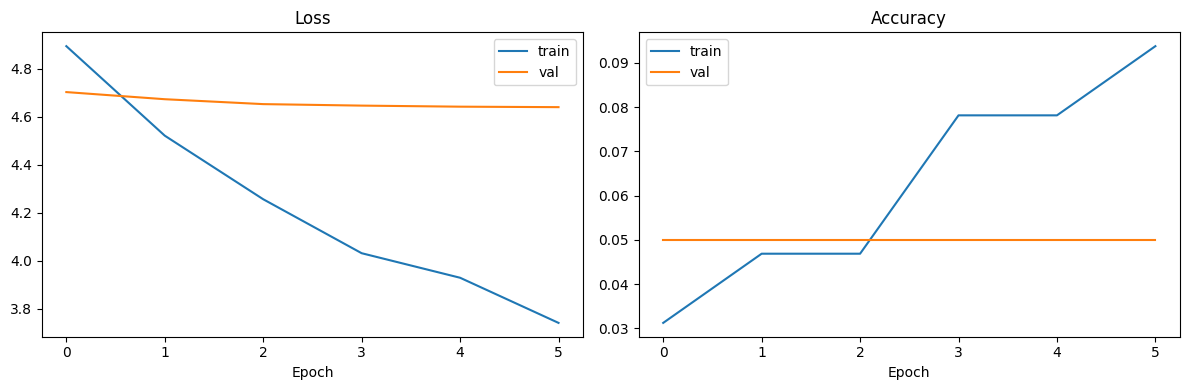

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(history.history["masked_accuracy"], label="train")
axes[1].plot(history.history["val_masked_accuracy"], label="val")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()

plt.tight_layout()
plt.savefig("training_curves.png")

In [94]:
# Save
model.save("plant_vlm_final.keras")

# Reload
loaded_model = tf.keras.models.load_model(
    "plant_vlm_final.keras",
    custom_objects={
        "PlantVLM": PlantVLM,
        "TransformerDecoderBlock": TransformerDecoderBlock,
        "masked_loss": masked_loss,
        "masked_accuracy": masked_accuracy,
    },
)

# Reload tokenizer
with open("tokenizer_vocab.json") as f:
    word_index = json.load(f)
index_word = {int(v): k for k, v in word_index.items()}

In [95]:
def generate_caption(model, image_path, word_index, index_word,
                     start_token, end_token, max_length=SEQ_LENGTH, temperature=1.0):
    img = load_and_preprocess_image(image_path)
    img = tf.expand_dims(img, 0)

    output_seq = [start_token]
    for _ in range(max_length):
        padded = pad_sequences([output_seq], maxlen=SEQ_LENGTH,
                               padding='post', truncating='post')
        preds = model.predict([img, padded], verbose=0)  # (1, SEQ_LENGTH, V)
        next_logits = preds[0, len(output_seq) - 1, :]

        # Greedy or sampled decoding
        if temperature == 1.0:
            next_id = int(tf.argmax(next_logits))
        else:
            logits = next_logits / temperature
            probs = tf.nn.softmax(logits).numpy()
            next_id = int(np.random.choice(len(probs), p=probs))

        if next_id == end_token:
            break
        output_seq.append(next_id)

    words = [index_word.get(t, "") for t in output_seq[1:]]
    return " ".join(w for w in words if w)

In [105]:
# Example
caption = generate_caption(
    loaded_model,
    image_path="./dataset/images/img4.jpeg",
    word_index=word_index,
    index_word=index_word,
    start_token=word_index["startseq"],
    end_token=word_index["endseq"],
    temperature=0.7,   # slight sampling for more natural variety
)
print("Generated:", caption)

Generated: in in treatment across leaf circular covered black purplish irregular scabs purplish this leaf treatment this its its the black purplish several dark olive showing olive several be a scab
